In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
df = pd.read_excel('ozon_databook_clean.xlsx')

In [ ]:

df.head(100)

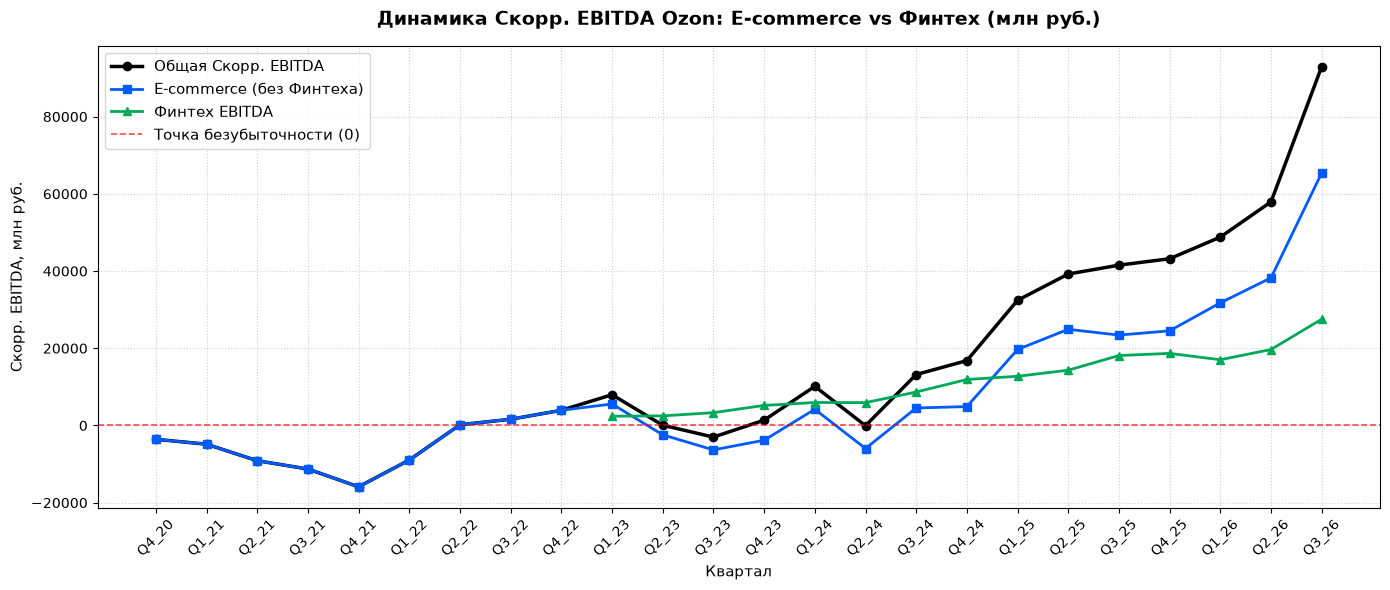

In [ ]:
# Считаем EBITDA чистого E-commerce (заполняем пустые значения Финтеха до 2023 года нулями)
fintech_ebitda = df['Финтех Скорр. показатель EBITDA'].fillna(0)
df['E-commerce EBITDA'] = df['Скорр. Показатель EBITDA'] - fintech_ebitda

# Настраиваем размер и стиль графика
plt.figure(figsize=(14, 6))

# Рисуем три линии для наглядности
plt.plot(df['Период'], df['Скорр. Показатель EBITDA'], label='Общая Скорр. EBITDA', color='black', linewidth=2.5, marker='o')
plt.plot(df['Период'], df['E-commerce EBITDA'], label='E-commerce (без Финтеха)', color='#005bff', linewidth=2, marker='s')
plt.plot(df['Период'], df['Финтех Скорр. показатель EBITDA'], label='Финтех EBITDA', color='#00a859', linewidth=2, marker='^')

# Добавляем нулевую линию (границу убытков и прибыли)
plt.axhline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Точка безубыточности (0)')

# Оформляем подписи и сетку
plt.title('Динамика Скорр. EBITDA Ozon: E-commerce vs Финтех (млн руб.)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Квартал', fontsize=11)
plt.ylabel('Скорр. EBITDA, млн руб.', fontsize=11)
plt.xticks(rotation=45) # Поворачиваем подписи кварталов, чтобы не наезжали друг на друга
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

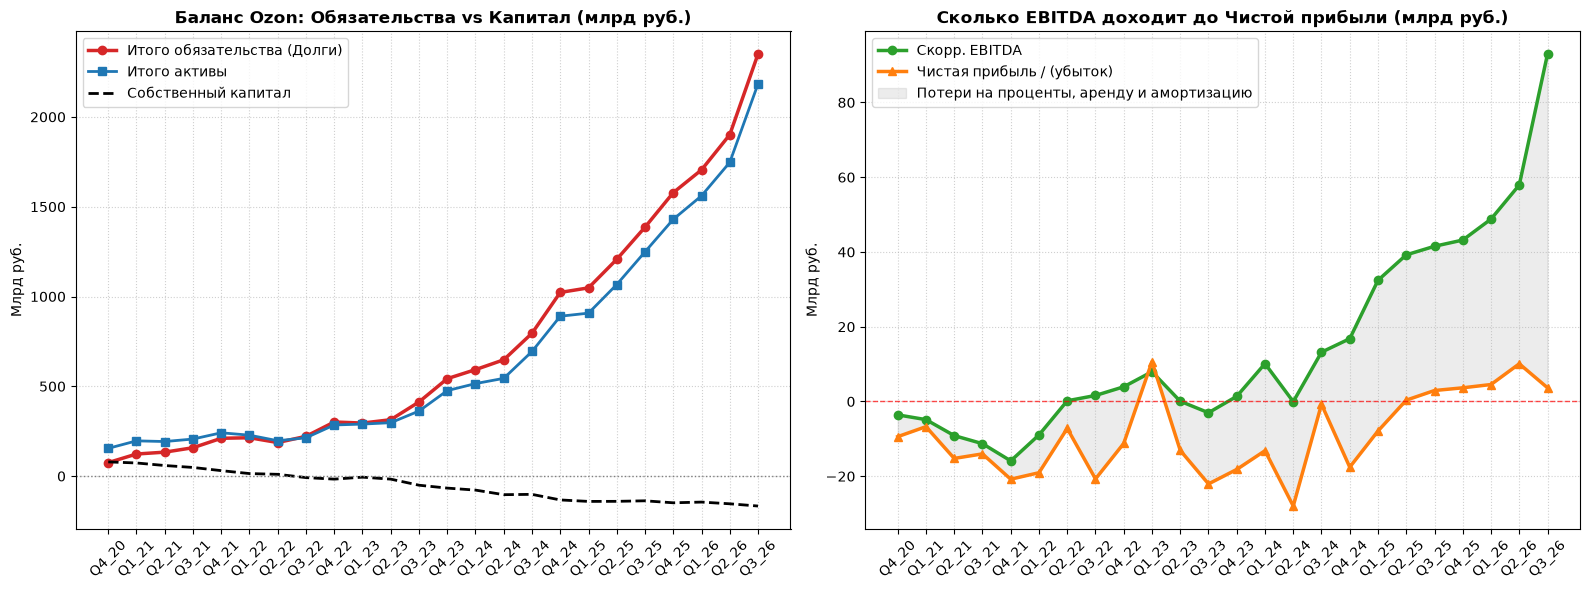

In [18]:
cap_col = [c for c in df.columns if 'Итого капитал' in c and 'обязательства' not in c]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- График 1: Активы, Обязательства и Отрицательный капитал ---
ax1.plot(df['Период'], df['Итого обязательства'] / 1000, label='Итого обязательства (Долги)', color='#d62728', linewidth=2.5, marker='o')
ax1.plot(df['Период'], df['Итого активы'] / 1000, label='Итого активы', color='#1f77b4', linewidth=2, marker='s')
ax1.plot(df['Период'], df[cap_col] / 1000, label='Собственный капитал', color='black', linewidth=2, linestyle='--')
ax1.axhline(0, color='gray', linestyle=':', linewidth=1)

ax1.set_title('Баланс Ozon: Обязательства vs Капитал (млрд руб.)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Млрд руб.')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# --- График 2: Скорр. EBITDA vs Реальная чистая прибыль ---
ax2.plot(df['Период'], df['Скорр. Показатель EBITDA'] / 1000, label='Скорр. EBITDA', color='#2ca02c', linewidth=2.5, marker='o')
ax2.plot(df['Период'], df['Прибыль/(убыток) за период'] / 1000, label='Чистая прибыль / (убыток)', color='#ff7f0e', linewidth=2.5, marker='^')
ax2.axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)

ax2.fill_between(
    df['Период'],
    df['Прибыль/(убыток) за период'] / 1000,
    df['Скорр. Показатель EBITDA'] / 1000,
    color='gray',
    alpha=0.15,
    label='Потери на проценты, аренду и амортизацию'
)

ax2.set_title('Сколько EBITDA доходит до Чистой прибыли (млрд руб.)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Млрд руб.')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

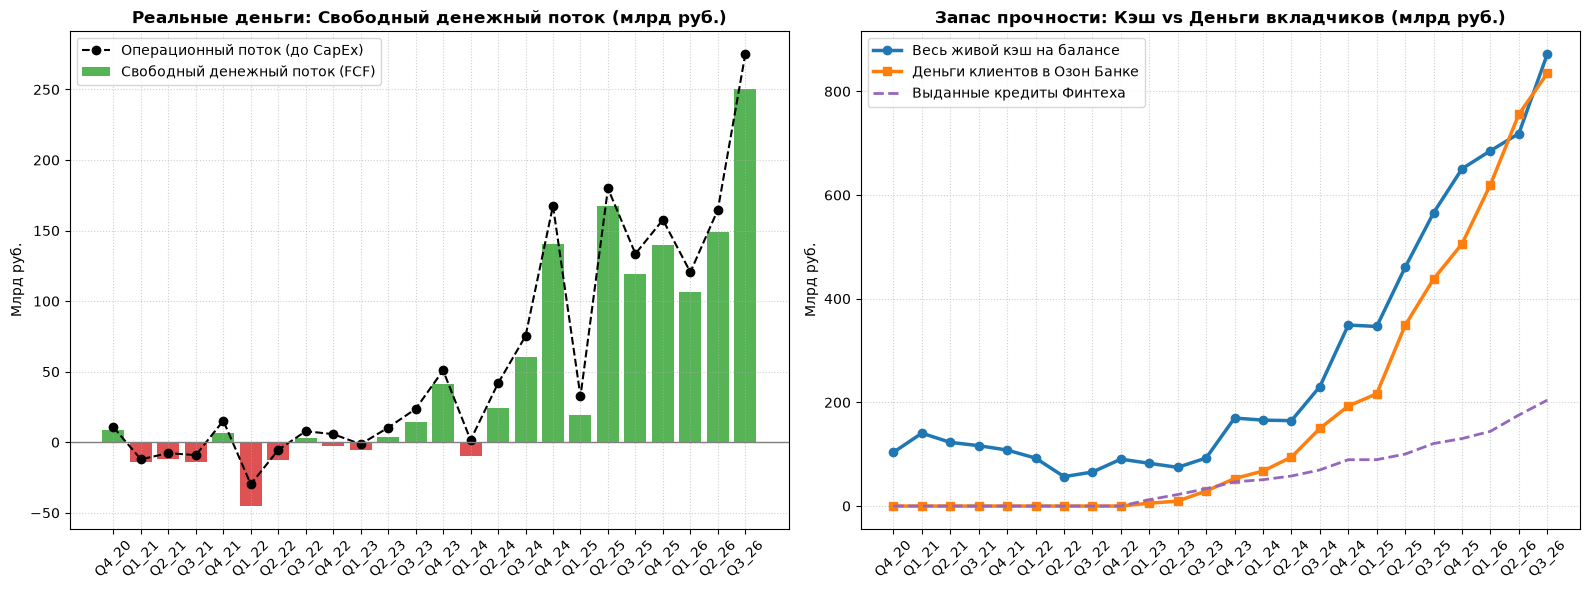

In [ ]:
# На всякий случай чистим пробелы в названиях столбцов
df.columns = df.columns.str.strip()

#  Считаем Свободный денежный поток (FCF = Операционный поток + Капитальные затраты, т.к. CapEx в таблице уже с минусом)
df['FCF'] = df['Чистый поток денежных средств от операционной деятельности'] + df['Капитальные затраты']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- График 1: Свободный денежный поток (FCF) ---
colors_fcf = ['#2ca02c' if val >= 0 else '#d62728' for val in df['FCF']]
ax1.bar(df['Период'], df['FCF'] / 1000, color=colors_fcf, alpha=0.8, label='Свободный денежный поток (FCF)')
ax1.plot(df['Период'], df['Чистый поток денежных средств от операционной деятельности'] / 1000, color='black', marker='o', linewidth=1.5, linestyle='--', label='Операционный поток (до CapEx)')
ax1.axhline(0, color='gray', linewidth=1)

ax1.set_title('Реальные деньги: Свободный денежный поток (млрд руб.)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Млрд руб.')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# --- График 2: Подушка безопасности (Кэш vs Деньги клиентов Финтеха) ---
ax2.plot(df['Период'], df['Денежные средства и их эквиваленты'] / 1000, label='Весь живой кэш на балансе', color='#1f77b4', linewidth=2.5, marker='o')
ax2.plot(df['Период'], df['Финтех Привлеченные средства клиентов'].fillna(0) / 1000, label='Деньги клиентов в Озон Банке', color='#ff7f0e', linewidth=2.5, marker='s')
ax2.plot(df['Период'], df['Финтех Кредиты и займы, выданные клиентам Финтеха'].fillna(0) / 1000, label='Выданные кредиты Финтеха', color='#9467bd', linewidth=2, linestyle='--')

ax2.set_title('Запас прочности: Кэш vs Деньги вкладчиков (млрд руб.)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Млрд руб.')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()